# Embeddings Demo


## Learning objectives

By the end of this demo, you should be able to:

1. Create an embedding and inspect its size.
2. Explain what changing the number of dimensions does.
3. Embed several texts in one call.
4. Measure similarity with cosine similarity.
5. Visualize how embeddings group related words.
6. Use similarity to find the most relevant text for a question (the core of RAG).

## Setup

In [3]:
# Setup
# numpy, scikit-learn and matplotlib are already installed in Colab\
!pip install -q openai

## 1. Add your OpenAI API key as a Colab secret (one time only)

Colab **Secrets** store your key safely, so you don't have to type it every time you run the notebook.

1. Click the **key icon** (🔑, "Secrets") in the left sidebar.
2. Click **+ Add new secret**.
3. **Name:** `OPENAI_API_KEY` (exactly this, in capitals). **Value:** your OpenAI API key.
4. Turn on **Notebook access** for this notebook.

If you already added this secret for another course notebook, just turn on **Notebook access** here.

> Never paste your API key directly into a code cell: it would be saved with the notebook and visible to anyone you share it with.

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from openai import OpenAI

def load_openai_key():
    """Read the OpenAI API key from Colab Secrets; ask for it only if that fails."""
    try:
        from google.colab import userdata
        return userdata.get("OPENAI_API_KEY")
    except ImportError:
        print("Not running in Colab.")
    except Exception as e:
        # e.g. the secret is missing, or Notebook access is turned off
        print(f"Could not read the Colab secret OPENAI_API_KEY ({type(e).__name__}).")
        print("Check the steps above: secret name, value, and Notebook access.")
    from getpass import getpass
    return getpass("Enter your OpenAI API key: ")

os.environ["OPENAI_API_KEY"] = load_openai_key()
client = OpenAI()

MODEL = "text-embedding-3-small"
print("OpenAI client is ready. Embedding model:", MODEL)

OpenAI client is ready. Embedding model: text-embedding-3-small


## 2. Getting an embedding

One text in, one vector out. The full vector has 1,536 numbers, so we print only its size and the first few values.

In [5]:
response = client.embeddings.create(
    input="Your text string goes here",
    model=MODEL,
)

full_vector = response.data[0].embedding
print("Dimensions:", len(full_vector))
print("First 5 values:", [round(v, 4) for v in full_vector[:5]])

Dimensions: 1536
First 5 values: [0.0051, 0.0172, -0.0187, -0.0186, -0.0473]


## 3. Changing the number of dimensions

**Discussion:** what happens if we ask for 100 dimensions instead of 1,536?

In [6]:
response = client.embeddings.create(
    input="Your text string goes here",
    model=MODEL,
    dimensions=100,
)

short_vector = response.data[0].embedding
print("Dimensions:", len(short_vector))
print("First 5 values:", [round(v, 4) for v in short_vector[:5]])

Dimensions: 100
First 5 values: [0.0179, 0.06, -0.0653, -0.0647, -0.1649]


**Answer:** for `text-embedding-3` models, the shorter vector is the **first 100 values of the full vector, rescaled to length 1**. That's why the first values above differ from section 2: they have been rescaled.

Shorter vectors are cheaper to store and faster to search, with a small loss in accuracy.

Let's check it: take the first 100 values of the full vector, rescale them, and compare with what the API returned.

In [7]:
manual = np.array(full_vector[:100])
manual = manual / np.linalg.norm(manual)   # rescale to length 1

api = np.array(short_vector)

print("Similarity between manual and API version:", round(float(manual @ api), 4))
# ~1.0 means they are the same vector (tiny differences are normal)

Similarity between manual and API version: 1.0003


## 4. Embedding several texts at once

The API accepts a list of texts and returns one vector per text, in the same order.

In [8]:
texts = [
    "Your text string goes here",
    "What is the annual leave policy?",
    "How do I submit an expense claim?",
]

response = client.embeddings.create(input=texts, model=MODEL)

embeddings = np.array([item.embedding for item in response.data])
print("Shape:", embeddings.shape, "(texts, dimensions)")

for text, vector in zip(texts, embeddings):
    print(f"{text:<36} -> first 3 values: {np.round(vector[:3], 4)}")

Shape: (3, 1536) (texts, dimensions)
Your text string goes here           -> first 3 values: [ 0.0052  0.0172 -0.0188]
What is the annual leave policy?     -> first 3 values: [-0.0162  0.0305  0.0492]
How do I submit an expense claim?    -> first 3 values: [-0.0332  0.0003  0.0205]


## 5. Cosine similarity

Cosine similarity measures how close two vectors are in direction (ignoring their length).

- **1.0**: same direction (very similar meaning)
- **0**: unrelated (at right angles)
- **−1**: opposite direction

In [9]:
import math

def cosine_similarity(a, b):
    dot = sum(x * y for x, y in zip(a, b))
    norm_a = math.sqrt(sum(x * x for x in a))
    norm_b = math.sqrt(sum(x * x for x in b))
    return dot / (norm_a * norm_b) if norm_a and norm_b else 0.0

In [10]:
# Quick sanity check with simple 2D vectors
cosine_similarity([1, 0], [1, 0])
# cosine_similarity([1, 0], [-1, 0])
#cosine_similarity([1, 0], [0, 1])
#cosine_similarity([1, 0], [1, 1])

1.0

## Comparing word embeddings

Let's embed a set of words and see how cosine similarity captures semantic relationships.

In [11]:
words = [
    "cat", "dog", "kitten", "puppy",
    "car", "automobile",
    "banana", "apple",
    "king", "queen", "man", "woman",
    "Paris", "France", "Tokyo", "Japan", "Singapore",
]

response = client.embeddings.create(
    model=MODEL,
    input=words,
)

embedding_by_word = {
    word: response.data[i].embedding
    for i, word in enumerate(words)
}

In [12]:
pairs = [
    ("cat", "dog"),
    ("kitten", "puppy"),
    ("car", "automobile"),
    ("king", "queen"),
    ("man", "woman"),
    ("Paris", "France"),
    ("Paris", "Singapore"),
    ("Tokyo", "Japan"),
    ("banana", "apple"),
    ("cat", "banana"),
    ("car", "king"),
    ("Paris", "puppy"),
    ("queen", "automobile"),
]

print("Cosine similarity (higher = more similar):\n")
for a, b in pairs:
    score = cosine_similarity(embedding_by_word[a], embedding_by_word[b])
    print(f"  {a:<12} {b:<12} {score:.3f}")

Cosine similarity (higher = more similar):

  cat          dog          0.603
  kitten       puppy        0.650
  car          automobile   0.556
  king         queen        0.591
  man          woman        0.707
  Paris        France       0.661
  Paris        Singapore    0.399
  Tokyo        Japan        0.471
  banana       apple        0.464
  cat          banana       0.298
  car          king         0.331
  Paris        puppy        0.204
  queen        automobile   0.219


**Discuss:** which pairs score highest? Notice that related pairs (cat/dog, man/woman, Paris/France) score clearly higher than unrelated ones (Paris/puppy, queen/automobile).

## 6. Visualize semantic relationships

Embeddings have 1,536 dimensions, which we can't plot. **PCA** squeezes them down to 2 dimensions so we can see which words sit close together. Some detail is lost, but the groups usually stay visible.

Original embedding shape: (17, 1536)
PCA shape: (17, 2)


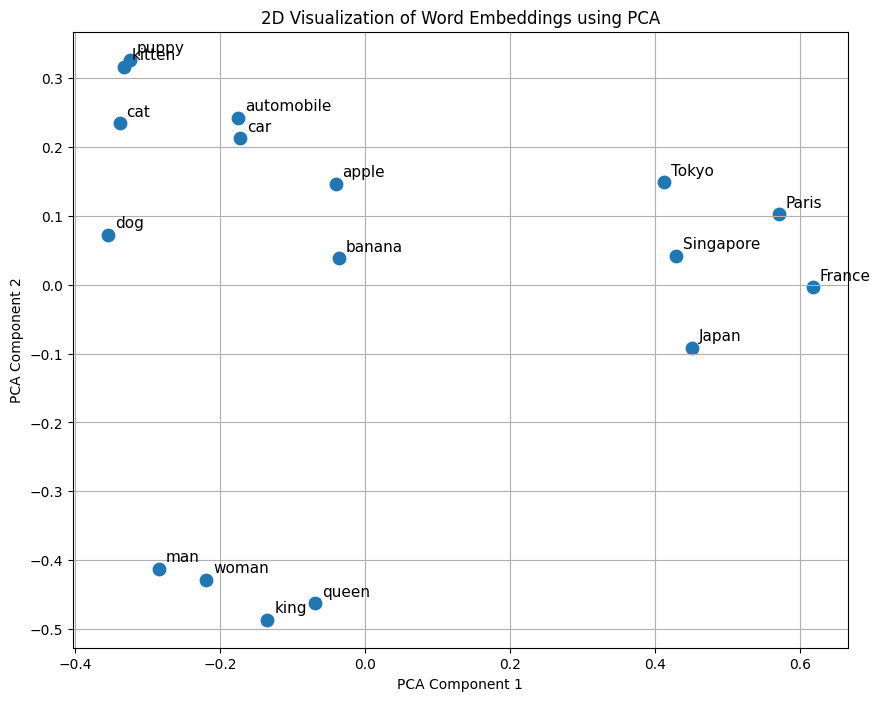

In [13]:
# 1. Get all unique words
words = sorted(set(word for pair in pairs for word in pair))

# 2. Get their embedding vectors
X = np.array([embedding_by_word[word] for word in words])

print("Original embedding shape:", X.shape)

# 3. Reduce embeddings to 2 dimensions using PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

print("PCA shape:", X_2d.shape)

# 4. Plot
plt.figure(figsize=(10, 8))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    s=80
)

# Add word labels
for i, word in enumerate(words):
    plt.annotate(
        word,
        (X_2d[i, 0], X_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=11
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("2D Visualization of Word Embeddings using PCA")
plt.grid(True)

plt.show()

## 7. From similarity to search (a preview of RAG)

RAG starts with exactly this step: embed the question, compare it with stored texts, and pick the closest one. Here the "stored texts" are four short help-desk questions.

In [15]:
documents = [
    "What is the annual leave policy?",
    "How do I submit an expense claim?",
    "How do I reset my password?",
    "Where is the nearest MRT station?",
]
question = "How many days off do I get each year?"

response = client.embeddings.create(input=documents + [question], model=MODEL)
doc_vectors = [item.embedding for item in response.data[:-1]]
question_vector = response.data[-1].embedding

scores = [cosine_similarity(question_vector, d) for d in doc_vectors]

print("Question:", question, "\n")
for score, doc in sorted(zip(scores, documents), reverse=True):
    print(f"  {score:.3f}  {doc}")

Question: How many days off do I get each year? 

  0.493  What is the annual leave policy?
  0.153  How do I reset my password?
  0.100  How do I submit an expense claim?
  0.028  Where is the nearest MRT station?


**Discuss:** the question shares almost no words with "What is the annual leave policy?", but it still ranks first. That is semantic search: matching by **meaning**, not by keywords.

In the RAG slides, the documents are chunks of real files stored in a **vector database**, and the closest chunks are added to the prompt.

The end.